# T cells: are they there, where are they, and do responders have more?

De novo clustering shows no T-cell cluster, and no annotation in the h5ad (`cell_class`, `cell_type`, cytetype)
has a lymphocyte label. The IHC, however, reported immune cells at the ventral meninges, the ventricle and the
internal capsule / thalamus. T cells are expected to be ~0.01-0.1 % of brain cells, far too few to form a cluster
among 980k cells, so here they are called per cell from marker co-expression. Module: `utils/tcells.py`.

* **A. Probe QC.** Which lymphocyte probes carry real signal and which are off-target?
* **B. Calls.** Cells with >= 3 core T-cell transcripts over >= 2 genes, against a within-section shuffle null.
* **C. What were they labelled as?** Their cell class / type / cytetype labels.
* **D. Where?** Whole-section maps, and close-ups with the Xenium cell polygons and transcripts.
* **E. Responders vs controls.** Density, position (borders vs tissue) and the oligodendrocyte-labelled fraction.

| input | made by | where |
|---|---|---|
| `results/tcells/*` | `scripts/export_tcells.py --h5ad ... --raw-dir .../raw_xenium/run4` | office Mac (`sopa` env, polars), 3 min |
| `results/cell_table/cells.csv.gz` | `scripts/export_cell_table.py` | office Mac, 1 min |

In [1]:
import sys, itertools
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.backends.backend_pdf import PdfPages
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import tcells as tc

IN = REPO / "results" / "tcells"; FIG = IN / "figures"; TAB = IN / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; ctrl = sections.index[grp == "control"]; resp = sections.index[grp == "responder"]
order = sections.sort_values(["condition", "age"]).index
panel = pd.read_csv(IN / "panel_summary.csv")
mc = pd.read_csv(IN / "marker_counts.csv.gz", index_col=0)
null = pd.read_csv(IN / "null_shuffle.csv")["n_called"]
T = mc[mc.tcell].copy()
T["border"] = T.RBD_compartment_simplified.isin(tc.BORDER_REGIONS)
T["ol_label"] = T.cell_class_updated.str.contains("Oligodendrocytes")

INK2, AXIS, GRID = "#52514e", "#c3c2b7", "#e1e0d9"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#d62728"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
CLASSES = sorted(set(mc.cell_class_updated) | set(pd.read_csv(IN / "zoom_cells.csv.gz", usecols=["cell_class_updated"]).cell_class_updated.dropna()))
CMAP = dict(zip(CLASSES, plt.get_cmap("tab20").colors))
TX_COL = {"Cd3d": RED, "Cd3e": RED, "Cd3g": RED, "Cd247": RED, "Cd8a": "#1f1fff", "Cd8b1": "#1f1fff",
          "Cxcr6": "#ff7f0e", "Lck": "#9400d3", "Itk": "#9400d3", "Cd2": "#9400d3", "Ptprc": "#000000"}
def save(fig, name, dpi=200):
    fig.savefig(FIG / f"{name}.png", dpi=dpi, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def perm_p(values, a, b, alternative="greater"):
    v = values.loc[list(a) + list(b)].to_numpy(); na = len(a)
    obs = v[:na].mean() - v[na:].mean()
    null = np.array([v[list(c)].mean() - np.delete(v, list(c)).mean() for c in itertools.combinations(range(len(v)), na)])
    if alternative == "two-sided":
        return float(np.mean(np.abs(null) >= abs(obs) - 1e-12)), obs
    return float(np.mean(null >= obs - 1e-12)), obs
def dots(ax, values, title, ylab=None):
    for gi, g in enumerate(GROUP_ORDER):
        v = values[values.index.map(grp) == g].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5); ax.set_title(title, fontsize=9)
    if ylab: ax.set_ylabel(ylab)
print(f"{len(T)} T cells called; shuffled null {null.mean():.1f} (max {null.max()}, {len(null)} reps)")

242 T cells called; shuffled null 3.9 (max 8, 20 reps)


## A. Probe QC: which lymphocyte probes can be trusted?

,role,total_counts,cells_ge1,top_class,top_class_frac,top_region,top_region_frac
gene,,,,,,,
Cd3d,core,738,589,Endothelial Cells,0.317,Meningeal border/glia limitans,0.216
Cd3e,core,359,331,Endothelial Cells,0.441,Meningeal border/glia limitans,0.399
Cd3g,core,695,561,Endothelial Cells,0.278,Cortex,0.196
Cd247,core,2105,1954,Neurons,0.654,Thalamus,0.713
Cd2,core,746,693,Endothelial Cells,0.222,Ventricular system,0.189
Cd8a,core,448,331,Excitatory Neurons,0.266,Cortex,0.242
Cd8b1,core,653,512,Excitatory Neurons,0.250,Cortex,0.236
Itk,core,1362,1302,Excitatory Neurons,0.284,Cortex,0.254
Cxcr6,core,604,412,Endothelial Cells,0.374,Meningeal border/glia limitans,0.267


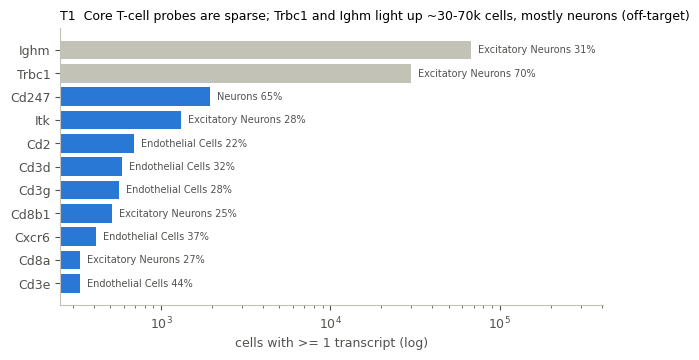

In [2]:
display(panel.set_index("gene")[["role", "total_counts", "cells_ge1", "top_class", "top_class_frac", "top_region", "top_region_frac"]])
p = panel[panel.role != "extra"].sort_values("cells_ge1")
fig, ax = plt.subplots(figsize=(7, 3.6))
cols = [AXIS if r == "noisy" else BLUE for r in p.role]
ax.barh(p.gene, p.cells_ge1, color=cols); ax.set_xscale("log")
for y, (_, r) in enumerate(p.iterrows()):
    ax.text(r.cells_ge1 * 1.1, y, f"{r.top_class} {r.top_class_frac:.0%}", va="center", fontsize=7, color=INK2)
ax.set_xlabel("cells with >= 1 transcript (log)"); ax.set_xlim(right=p.cells_ge1.max() * 6)
ax.set_title("T1  Core T-cell probes are sparse; Trbc1 and Ighm light up ~30-70k cells, mostly neurons (off-target)", fontsize=9)
save(fig, "T1_probe_qc")

**A.** The two probes that would make a naive score, **Trbc1** (TCR beta) and **Ighm** (IgM heavy chain), are detected
in 30k and 68k cells, 70 % / 31 % of them excitatory neurons in cortex: off-target signal, unusable. A Cd3/TCR score
that includes Trbc1 calls ~6,000 "T cells", almost all cortical neurons. The core genes (Cd3d/e/g, Cd8a/b1, Cd2, Itk,
Cxcr6) are detected in only 300-1,300 cells each, scattered single transcripts in most of them; Cd247 and Itk also
carry diffuse neuronal background. `Trac` and `Nkg7` are not in the panel. Hence the call below needs co-expression.

## B. Calls: co-expression of core genes, against a within-section shuffle null

,>= 1 genes,>= 2 genes,>= 3 genes
min core transcripts,,,
2,513,320,208
3,266,242,208
4,205,198,187
5,167,166,160


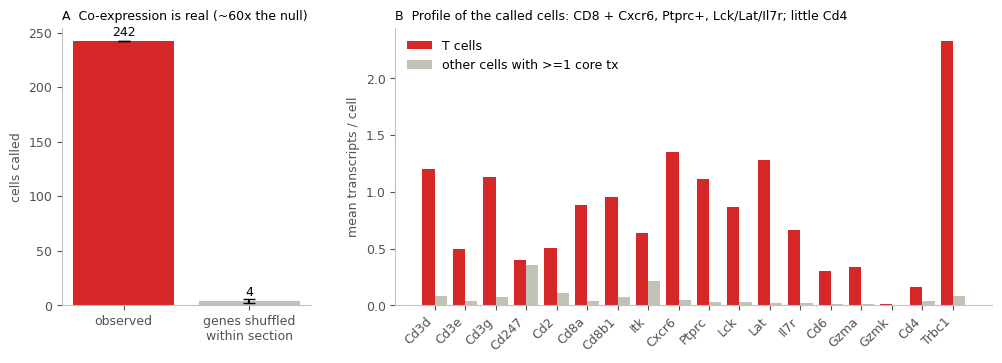

In [3]:
core = mc[tc.CORE]
grid = pd.DataFrame({g: [int(tc.call_tcells(core, min_tx=t, min_genes=g).sum()) for t in (2, 3, 4, 5)] for g in (1, 2, 3)},
                    index=pd.Index([2, 3, 4, 5], name="min core transcripts")).rename(columns=lambda g: f">= {g} genes")
display(save_table(grid, "threshold_grid"))
prof = pd.DataFrame({"T cells": T[tc.CORE + ["Ptprc", "Lck", "Lat", "Il7r", "Cd6", "Gzma", "Gzmk", "Cd4", "Trbc1"]].mean(),
                     "other cells with >=1 core tx": mc[~mc.tcell][tc.CORE + ["Ptprc", "Lck", "Lat", "Il7r", "Cd6", "Gzma", "Gzmk", "Cd4", "Trbc1"]].mean()})
save_table(prof.round(3), "expression_profile")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 2.4]})
ax = axes[0]
ax.bar([0, 1], [len(T), null.mean()], color=[RED, AXIS], yerr=[0, null.std()], capsize=4)
ax.set_xticks([0, 1], ["observed", "genes shuffled\nwithin section"]); ax.set_ylabel("cells called")
for x, v in [(0, len(T)), (1, null.mean())]: ax.text(x, v + 5, f"{v:.0f}", ha="center")
ax.set_title("A  Co-expression is real (~60x the null)", fontsize=9)
ax = axes[1]
x = np.arange(len(prof)); ax.bar(x - 0.2, prof.iloc[:, 0], 0.4, color=RED, label=prof.columns[0])
ax.bar(x + 0.2, prof.iloc[:, 1], 0.4, color=AXIS, label=prof.columns[1])
ax.set_xticks(x, prof.index, rotation=45, ha="right"); ax.set_ylabel("mean transcripts / cell"); ax.legend(frameon=False)
ax.set_title("B  Profile of the called cells: CD8 + Cxcr6, Ptprc+, Lck/Lat/Il7r; little Cd4", fontsize=9)
save(fig, "T2_calls_and_profile")

**B.** 242 cells pass (>= 3 core transcripts, >= 2 different genes) against ~4 when each gene is shuffled across the
cells of its section, so these are real co-expressing cells, not coincident scattered transcripts. The count is
stable around the default (see `threshold_grid`); the relaxed rule (>= 2 transcripts, >= 2 genes) adds ~80 cells at
a ~20-cell null. The called cells are CD8 (Cd8a/b1) with Cxcr6, Ptprc, Lck, Lat and Il7r and some Gzma, the profile of
tissue-resident memory CD8 T cells that patrol the brain borders; Cd4 is low (and mostly striatal-neuron background
elsewhere), so CD4 T cells are rare or undetectable. Trbc1 *is* high in the called cells (2.3 per cell): the probe
works in T cells, it is just swamped by neuronal background. ~2.5 per 10k cells: ordinary for a healthy mouse brain.

## C. What were they labelled as?

,T cells
cell_class_updated,
Endothelial Cells,133
Astrocytes,44
DA-Oligodendrocytes,37
Oligodendrocytes,6
Myocytes,5
Microglia,4
Excitatory Neurons,3
Neural Stem Cells,3


,T cells
cell_type,
Vascular leptomeningeal cells I,88
Mature oligodendrocytes V,40
Vascular endothelial cells I,34
Endothelial cells I,28
Telencephalon astrocytes II,9
Pericytes I,7
Chorid plexus epithelial cells I,7
Unknown,6


,T cells
cytetype_annotation_leiden_3,
Stress-Responsive Oligodendrocyte (GFAP-elevated),39
Leptomeningeal Cell,35
Perivascular Astrocyte,34
Astrocyte (reactive),32
Hybrid Vascular Endothelial Cell,27
Meningeal Vascular Endothelial Cell,23
Astrocyte (demyelination-responsive),9
Choroid Plexus Epithelial Cell,7


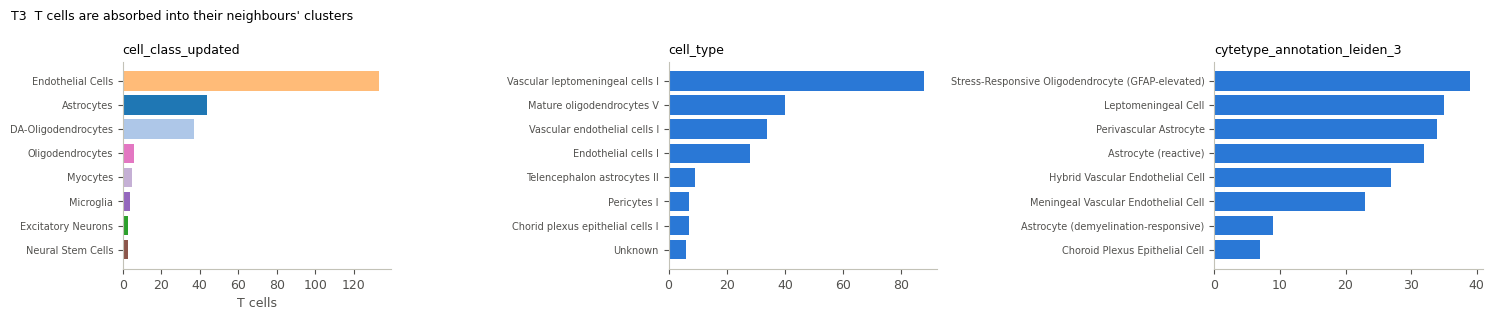

In [4]:
lab = {}
for col in ["cell_class_updated", "cell_type", "cytetype_annotation_leiden_3"]:
    lab[col] = T[col].value_counts().head(8)
    display(lab[col].rename(col).to_frame("T cells"))
save_table(pd.concat({k: v for k, v in lab.items()}, names=["column", "label"]).rename("n_tcells").to_frame(), "labels")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, (col, v) in zip(axes, lab.items()):
    v = v[::-1]; ax.barh(v.index, v.values, color=[CMAP.get(i, AXIS) if col == "cell_class_updated" else BLUE for i in v.index])
    ax.set_title(col, fontsize=9); ax.tick_params(axis="y", labelsize=7)
axes[0].set_xlabel("T cells"); fig.suptitle("T3  T cells are absorbed into their neighbours' clusters", x=0.01, ha="left", fontsize=9)
fig.tight_layout(); save(fig, "T3_labels")

**C.** No T cell carries a lymphocyte label at any level. 55 % sit in endothelial / vascular leptomeningeal clusters,
18 % in astrocytes and 15 % in the DA-Oligodendrocyte cluster ("Mature oligodendrocytes V", cytetype's
"Stress-Responsive Oligodendrocyte (GFAP-elevated)"). Leiden at every resolution (0.5-3) splits them over the same
2-5 large clusters. Too few to cluster; they are classified by what surrounds them.

## D. Where are they? Whole sections, then close-ups with the Xenium polygons

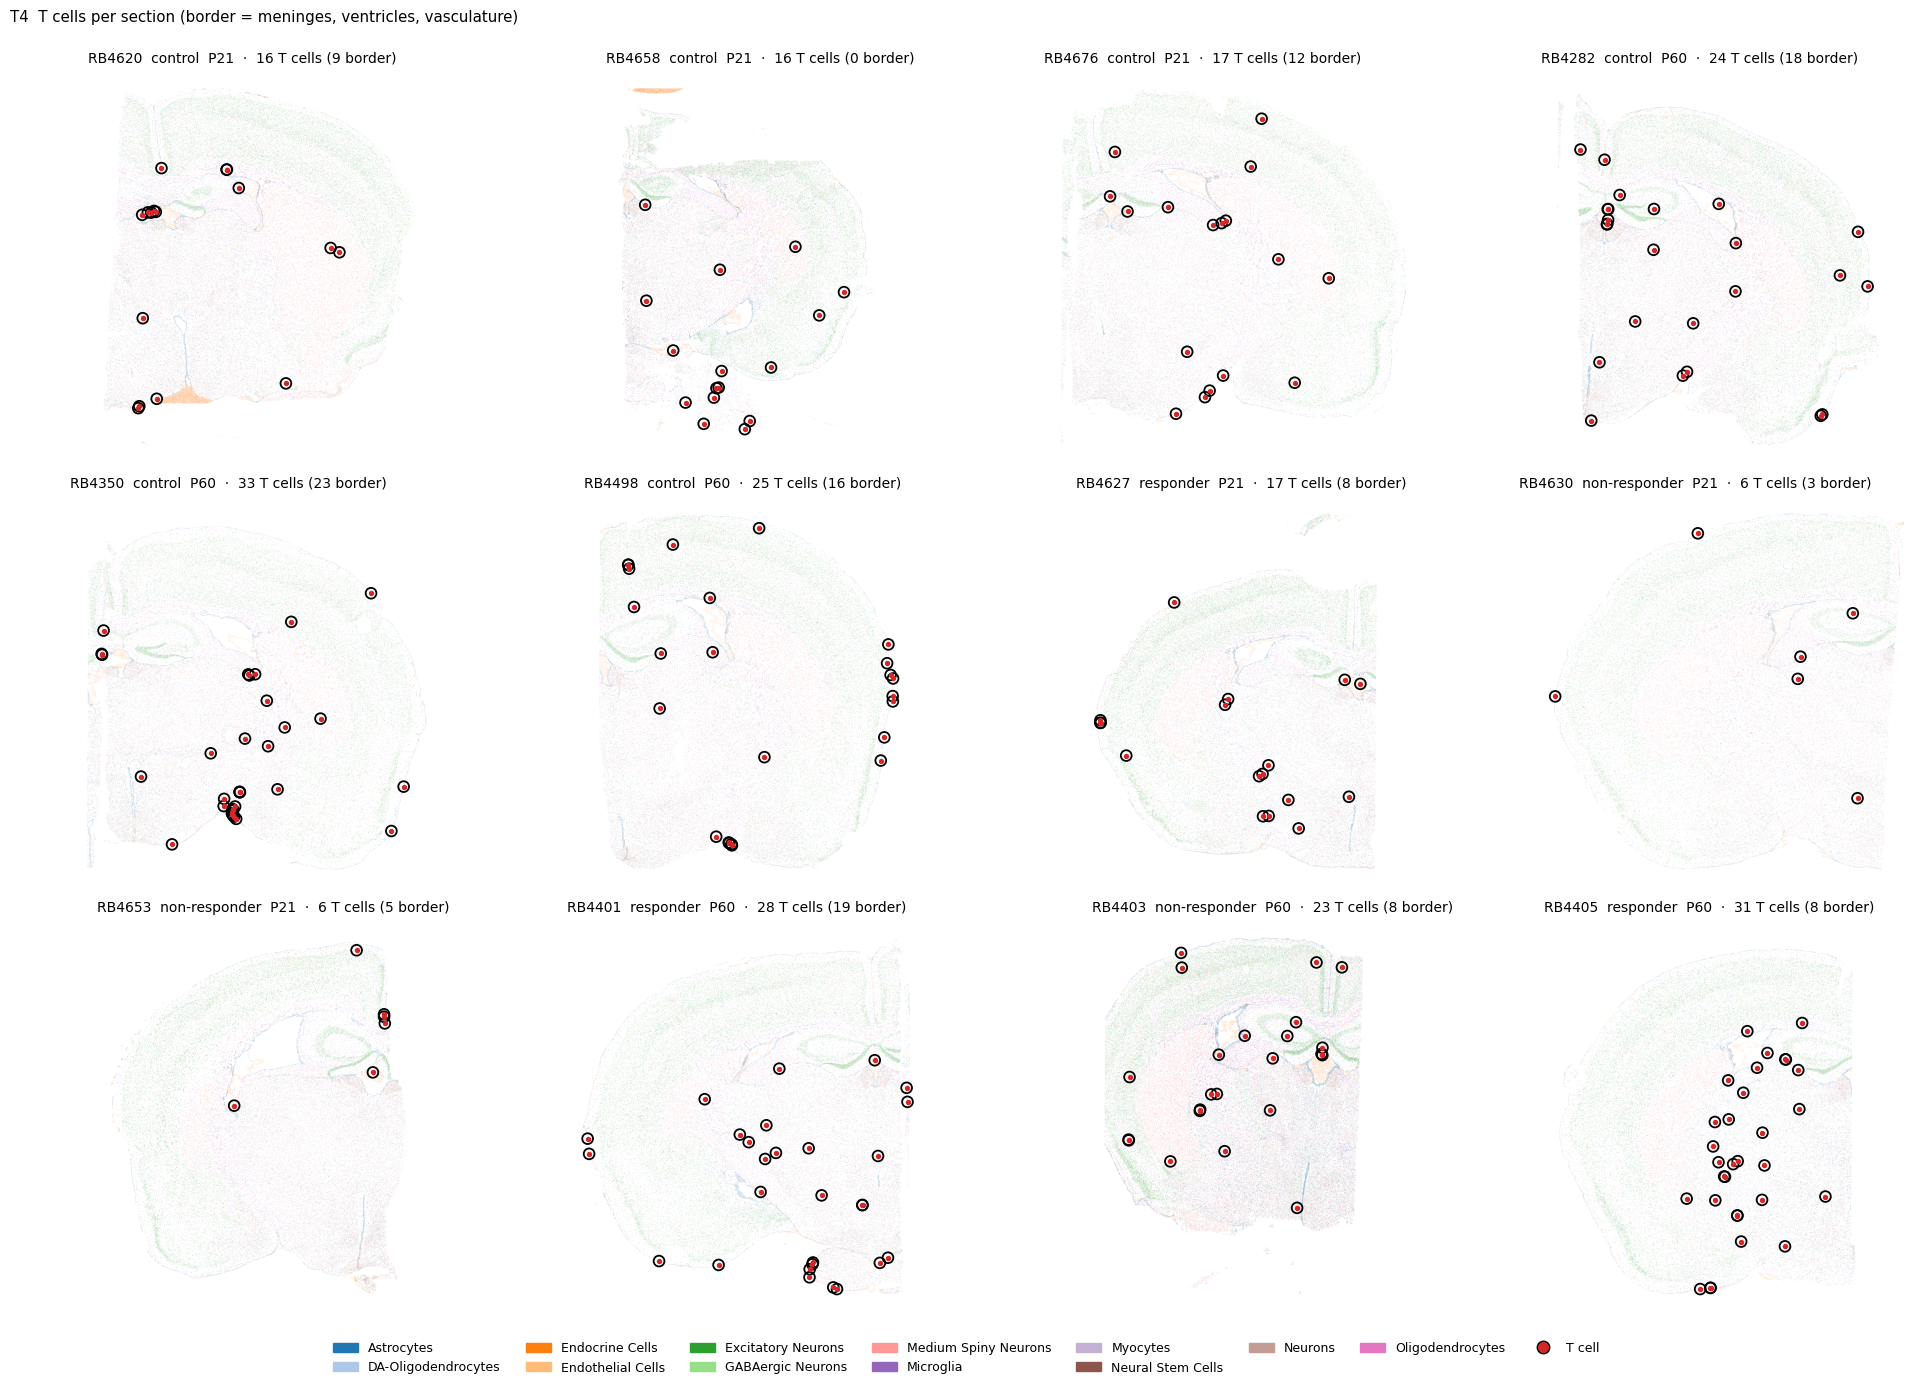

In [5]:
cells = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz", usecols=["sample_id", "cell_class", "x_centroid", "y_centroid"])
fig, axs = plt.subplots(3, 4, figsize=(20, 14))
for ax, smp in zip(axs.flat, order):
    o = cells[cells.sample_id == smp]; t = T[T.sample_id == smp]
    ax.scatter(o.x_centroid, o.y_centroid, s=0.12, c=[CMAP.get(c, AXIS) for c in o.cell_class], alpha=0.3, rasterized=True, linewidths=0)
    ax.scatter(t.x_centroid, t.y_centroid, s=60, facecolors="none", edgecolors="k", linewidths=1.3)
    ax.scatter(t.x_centroid, t.y_centroid, s=8, c=RED)
    ax.set_title(f"{smp}  {grp[smp]}  P{sections.age[smp]}  ·  {len(t)} T cells ({t.border.sum()} border)", fontsize=10)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
fig.legend(handles=[Patch(color=CMAP[c], label=c) for c in CLASSES if c in set(cells.cell_class)] +
           [Line2D([], [], marker="o", ls="", mfc=RED, mec="k", ms=9, label="T cell")], loc="lower center", ncol=8, frameon=False)
fig.suptitle("T4  T cells per section (border = meninges, ventricles, vasculature)", x=0.01, ha="left")
plt.tight_layout(rect=[0, 0.04, 1, 0.98]); save(fig, "T4_overview", dpi=110)

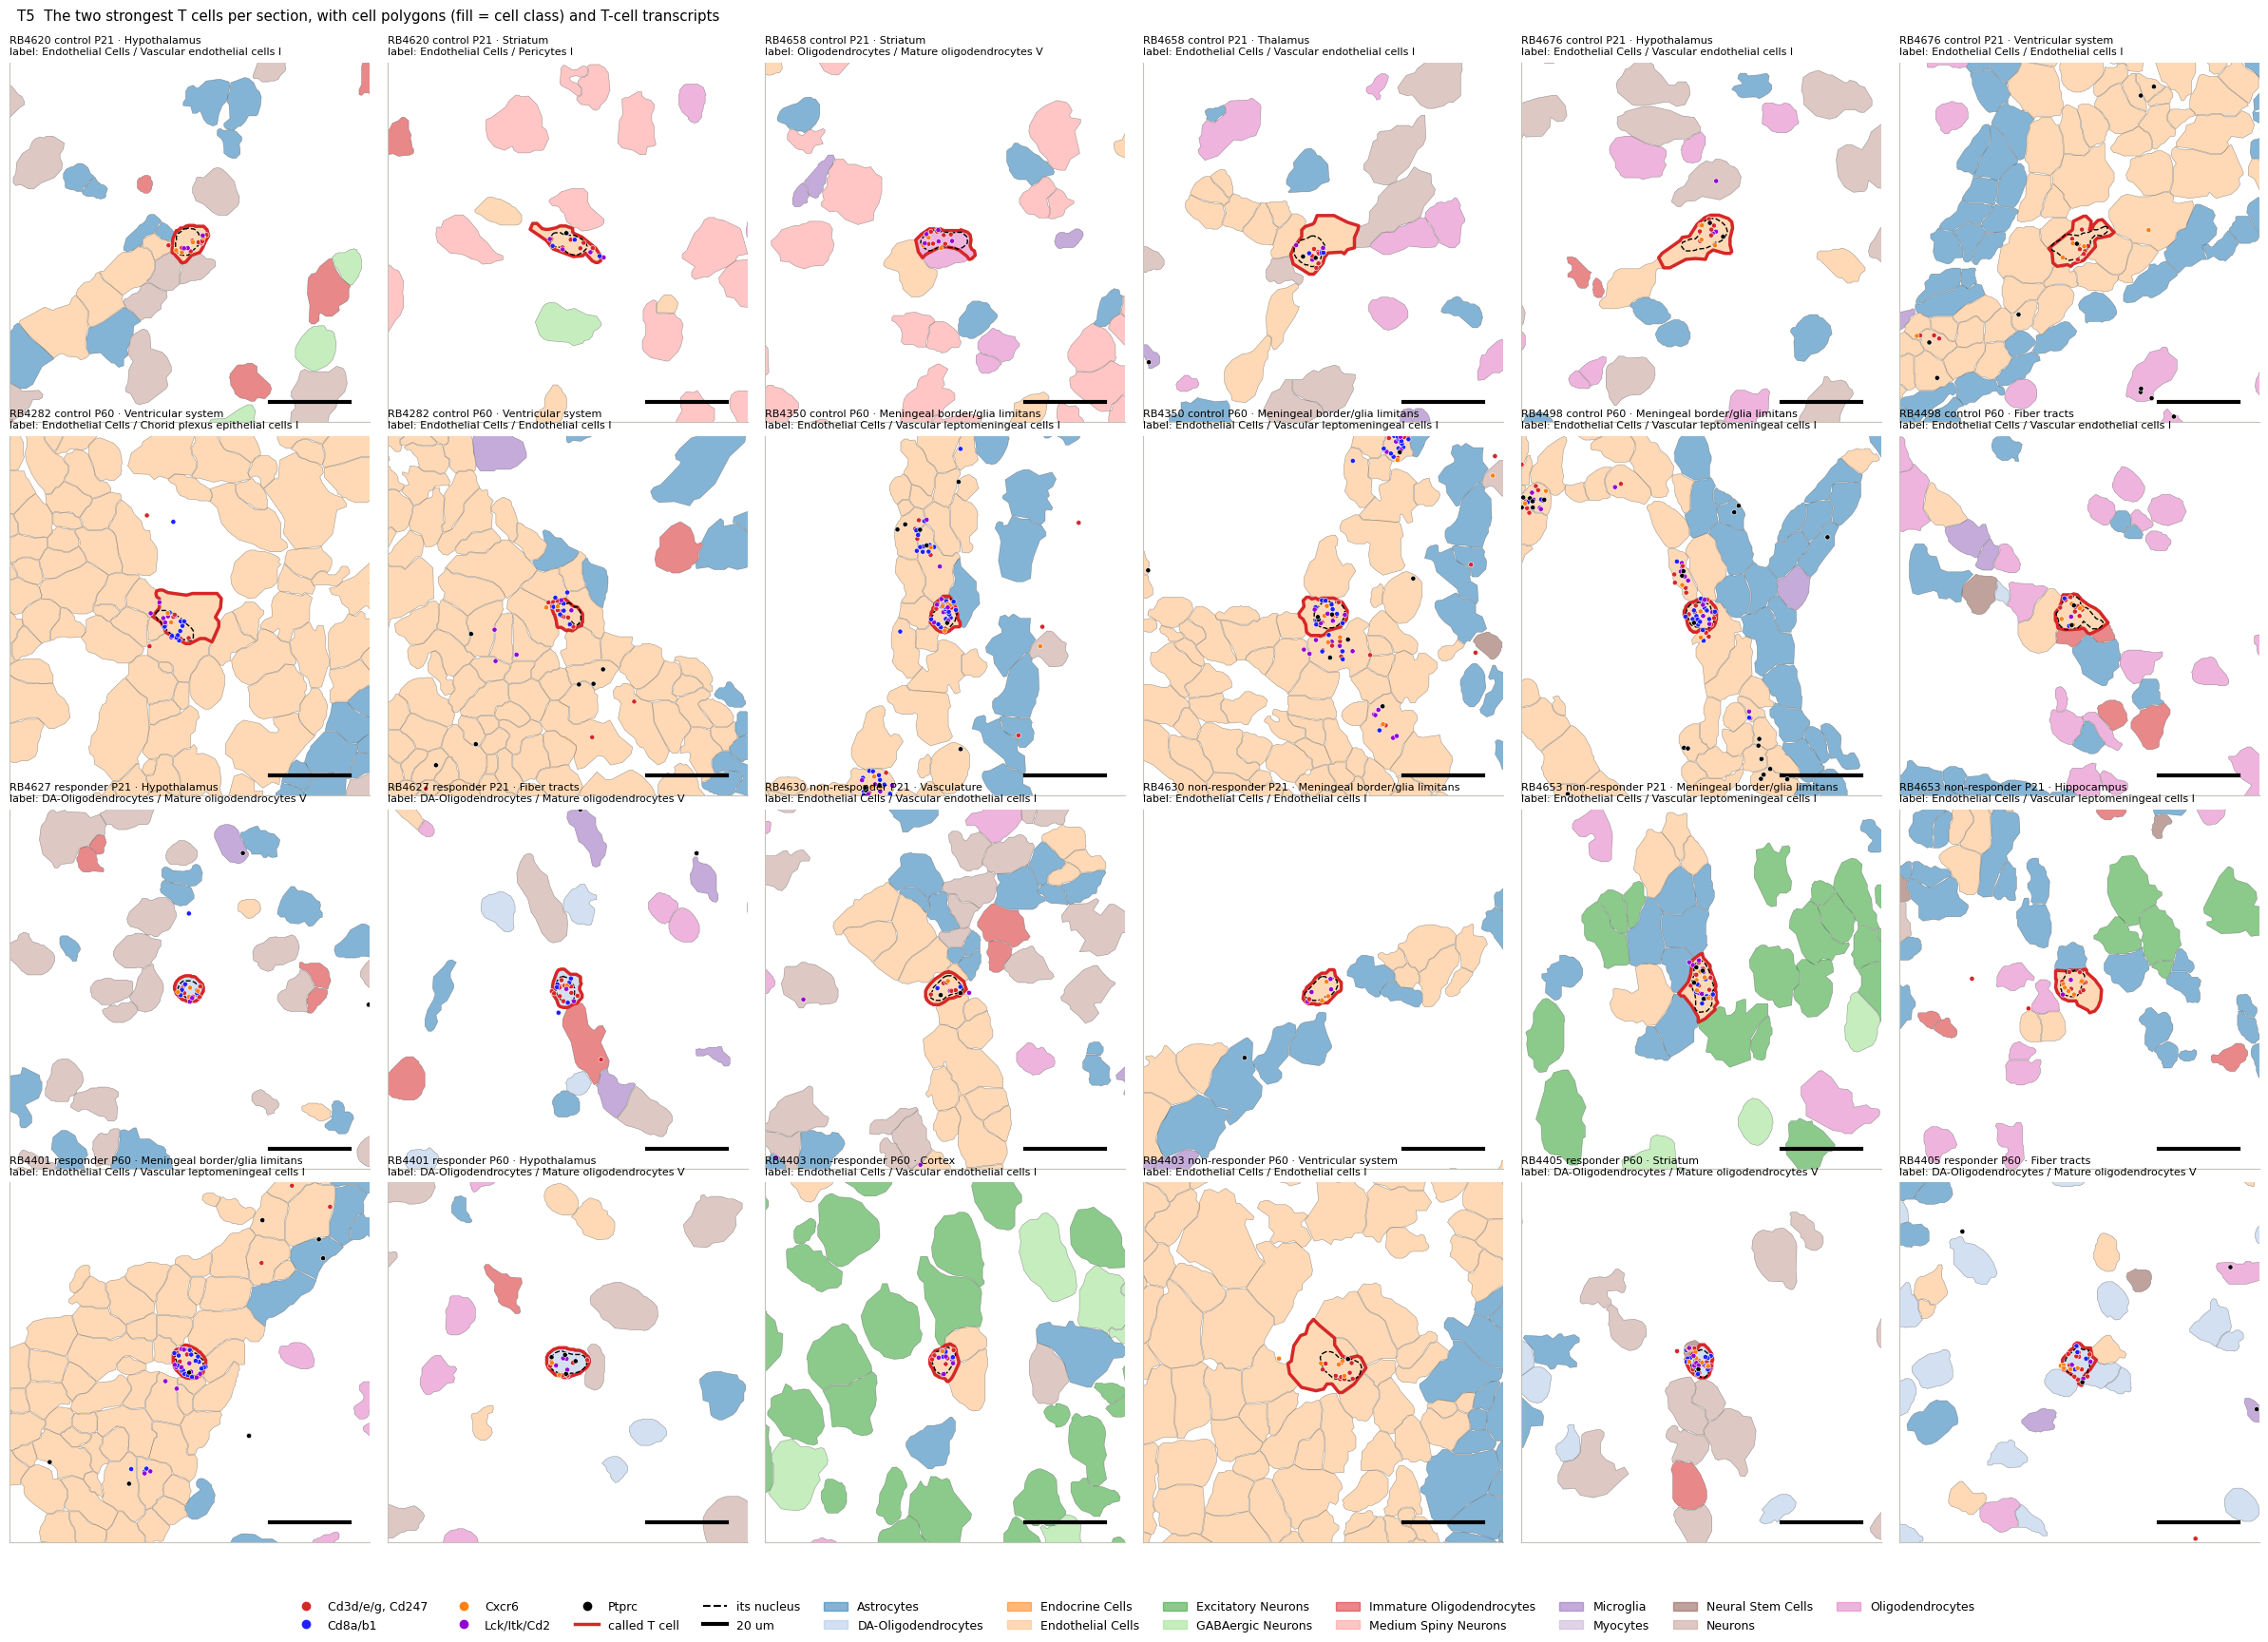

In [6]:
zc = pd.read_csv(IN / "zoom_cells.csv.gz"); zn = pd.read_csv(IN / "zoom_nuclei.csv.gz"); zt = pd.read_csv(IN / "zoom_transcripts.csv.gz")
zc_by = dict(tuple(zc.groupby("sample_id"))); zn_by = dict(tuple(zn.groupby(["sample_id", "cell_id"])))
zt_by = dict(tuple(zt.groupby("sample_id")))
W = 45
def zoom(ax, r):
    x, y = r.x_centroid, r.y_centroid
    c = zc_by[r.sample_id]; c = c[c.cell_id.isin(c.loc[c.vertex_x.between(x - W - 15, x + W + 15) & c.vertex_y.between(y - W - 15, y + W + 15), "cell_id"])]
    polys, fc = [], []
    for cid, g in c.groupby("cell_id", sort=False):
        polys.append(g[["vertex_x", "vertex_y"]].to_numpy()); fc.append(CMAP.get(g.cell_class_updated.iloc[0], "#dddddd"))
    ax.add_collection(PolyCollection(polys, facecolors=fc, edgecolors="#555555", linewidths=0.4, alpha=0.55))
    me = c[c.cell_id == r.cell_id][["vertex_x", "vertex_y"]].to_numpy()
    ax.add_collection(PolyCollection([me], facecolors="none", edgecolors=RED, linewidths=2.5))
    nu = zn_by.get((r.sample_id, r.cell_id))
    if nu is not None:
        ax.add_collection(PolyCollection([nu[["vertex_x", "vertex_y"]].to_numpy()], facecolors="none", edgecolors="k", linewidths=1, linestyles="--"))
    t = zt_by.get(r.sample_id, zt.iloc[:0]); t = t[t.x_location.between(x - W, x + W) & t.y_location.between(y - W, y + W)]
    ax.scatter(t.x_location, t.y_location, s=14, c=[TX_COL[g] for g in t.feature_name], edgecolors="white", linewidths=0.4, zorder=5)
    ax.set_xlim(x - W, x + W); ax.set_ylim(y + W, y - W); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.plot([x + W - 25, x + W - 5], [y + W - 5] * 2, c="k", lw=3)
    ax.set_title(f"{r.sample_id} {grp[r.sample_id]} P{r.age} · {r.RBD_compartment_simplified}\nlabel: {r.cell_class_updated} / {r.cell_type}", fontsize=8)
ZLEG = [Line2D([], [], marker="o", ls="", mfc=c, mec="w", ms=8, label=l) for l, c in
        [("Cd3d/e/g, Cd247", RED), ("Cd8a/b1", "#1f1fff"), ("Cxcr6", "#ff7f0e"), ("Lck/Itk/Cd2", "#9400d3"), ("Ptprc", "#000000")]]
ZLEG += [Line2D([], [], c=RED, lw=2.5, label="called T cell"), Line2D([], [], c="k", ls="--", label="its nucleus"), Line2D([], [], c="k", lw=3, label="20 um")]
ZLEG += [Patch(color=CMAP[c], alpha=0.55, label=c) for c in CLASSES]

picks = T.assign(core=T[tc.CORE].sum(1)).sort_values("core", ascending=False).groupby("sample_id").head(2)
picks = pd.concat([picks[picks.sample_id == s] for s in order])
fig, axs = plt.subplots(4, 6, figsize=(24, 17.5))
for ax, (_, r) in zip(axs.flat, picks.iterrows()): zoom(ax, r)
for ax in axs.flat[len(picks):]: ax.axis("off")
fig.legend(handles=ZLEG, loc="lower center", ncol=11, fontsize=9, frameon=False)
fig.suptitle("T5  The two strongest T cells per section, with cell polygons (fill = cell class) and T-cell transcripts", x=0.01, ha="left")
plt.tight_layout(rect=[0, 0.05, 1, 0.98]); save(fig, "T5_polygon_zooms")

with PdfPages(FIG / "T5b_all_tcells_polygon_zooms.pdf") as pdf:   # every called T cell, 24 per page
    allT = pd.concat([T[T.sample_id == s] for s in order])
    for i in range(0, len(allT), 24):
        f, axs = plt.subplots(4, 6, figsize=(24, 17.5))
        for ax, (_, r) in zip(axs.flat, allT.iloc[i:i + 24].iterrows()): zoom(ax, r)
        for ax in axs.flat[len(allT.iloc[i:i + 24]):]: ax.axis("off")
        f.legend(handles=ZLEG, loc="lower center", ncol=11, fontsize=9, frameon=False)
        f.tight_layout(rect=[0, 0.05, 1, 1]); pdf.savefig(f); plt.close(f)

**D.** The called cells look like lymphocytes: small and round (~8-12 um), with their Cd3 / Cd8 / Cxcr6 transcripts
inside the polygon and around the nucleus, not a smear from a neighbour. The endothelial-labelled ones sit in rows of
endothelial or leptomeningeal cells, i.e. in or along vessels and the meninges (possibly still intravascular). The
oligodendrocyte-labelled ones are isolated cells in the tissue (striatum, hypothalamus, fibre tracts) surrounded by
OLs, mislabelled by their neighbourhood. Every called T cell is in `figures/T5b_all_tcells_polygon_zooms.pdf`.

## E. Responders vs controls: density, position and OL contact

,n,border,ol_label,n_cells,group,age,per_10k,tissue_per_10k,frac_tissue,frac_ol_label
sample_id,,,,,,,,,,
RB4620,16,9,2,88718,control,21,1.80,0.79,0.44,0.12
RB4658,16,0,3,71184,control,21,2.25,2.25,1.00,0.19
RB4676,17,12,1,81758,control,21,2.08,0.61,0.29,0.06
RB4282,24,18,0,81721,control,60,2.94,0.73,0.25,0.00
RB4350,33,23,5,72889,control,60,4.53,1.37,0.30,0.15
RB4498,25,16,4,75676,control,60,3.30,1.19,0.36,0.16
RB4627,17,8,7,72848,responder,21,2.33,1.24,0.53,0.41
RB4630,6,3,1,69913,non-responder,21,0.86,0.43,0.50,0.17
RB4653,6,5,0,77245,non-responder,21,0.78,0.13,0.17,0.00


,metric,control,responder,non-responder,perm_p_two_sided
0,per_10k,2.816,3.351,1.111,0.464
1,tissue_per_10k,1.157,1.819,0.556,0.286
2,frac_tissue,0.441,0.531,0.440,0.702
3,frac_ol_label,0.114,0.302,0.128,0.060


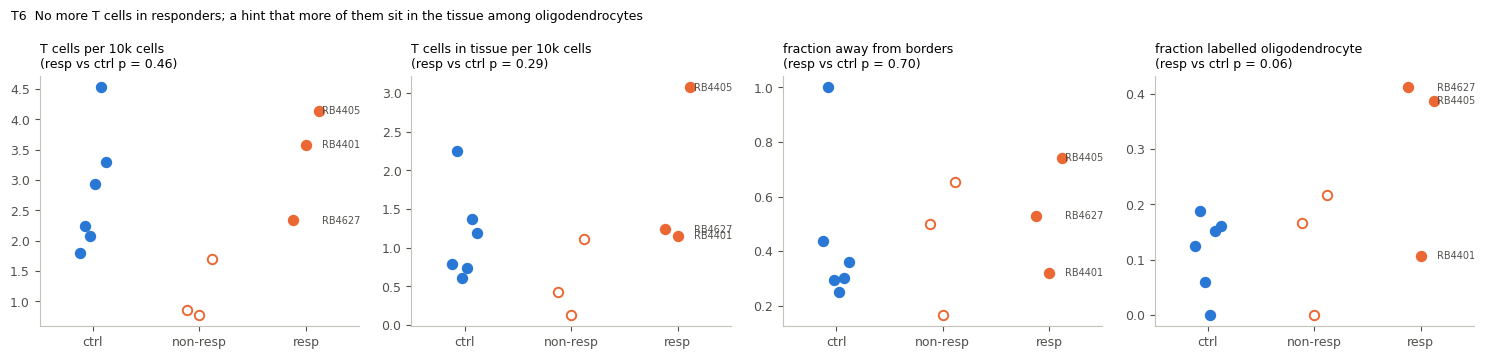

In [7]:
per = T.groupby("sample_id").agg(n=("tcell", "size"), border=("border", "sum"), ol_label=("ol_label", "sum")).reindex(sections.index, fill_value=0)
per["n_cells"] = sections.n_cells; per["group"] = grp; per["age"] = sections.age
per["per_10k"] = 1e4 * per.n / per.n_cells
per["tissue_per_10k"] = 1e4 * (per.n - per.border) / per.n_cells
per["frac_tissue"] = (per.n - per.border) / per.n
per["frac_ol_label"] = per.ol_label / per.n
save_table(per.loc[order].round(3), "per_section")
display(per.loc[order].round(2))
rows = []
for m in ["per_10k", "tissue_per_10k", "frac_tissue", "frac_ol_label"]:
    p, diff = perm_p(per[m], resp, ctrl, "two-sided")
    rows.append({"metric": m, "control": per.loc[ctrl, m].mean(), "responder": per.loc[resp, m].mean(),
                 "non-responder": per.loc[grp == "non-responder", m].mean(), "perm_p_two_sided": p})
summ = save_table(pd.DataFrame(rows).round(3), "responder_vs_control", index=False)
display(summ)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (m, lab) in zip(axes, [("per_10k", "T cells per 10k cells"), ("tissue_per_10k", "T cells in tissue per 10k cells"),
                               ("frac_tissue", "fraction away from borders"), ("frac_ol_label", "fraction labelled oligodendrocyte")]):
    p = summ.set_index("metric").loc[m, "perm_p_two_sided"]
    dots(ax, per[m], f"{lab}\n(resp vs ctrl p = {p:.2f})")
    for s in resp: ax.annotate(s, (2.15, per.loc[s, m]), fontsize=7, color=INK2, va="center")
fig.suptitle("T6  No more T cells in responders; a hint that more of them sit in the tissue among oligodendrocytes", x=0.01, ha="left", fontsize=9)
fig.tight_layout(); save(fig, "T6_responders_vs_controls")

**E.** Responders do **not** have more T cells (3.4 vs 2.8 per 10k in controls, p = 0.46; 84 relabellings, floor
p = 0.012); the three non-responders have the fewest (0.8-1.7). What differs is *where* they are in two of the three
responders: in RB4627 and RB4405, ~40 % of the T cells are labelled oligodendrocyte (controls 0-19 %, p = 0.06), and
RB4405 has the most T cells inside the tissue (3.1 per 10k vs <= 2.2 in any control); RB4401 looks like a control.
The "away from borders" fraction is unreliable for RB4658, whose region map has no meningeal / ventricular cells under
its edge T cells (fraction 1.0 is an annotation artefact). With 3 responders and ~10-30 T cells per section this is a
hint to check against the IHC, not a result.

## Summary

* T cells are present but rare: **242 of 980k cells** (~2.5 per 10k), CD8 / Cxcr6 tissue-resident type, mostly at the
  meninges, ventricles and along vessels. Calls rest on co-expression of >= 2 core genes; the shuffle null gives ~4.
* They cannot be found by clustering and carry their neighbours' labels (endothelial / leptomeningeal 55 %,
  astrocyte 18 %, DA-oligodendrocyte 15 %).
* Trbc1 and Ighm are dominated by off-target neuronal signal; never use them alone as lymphocyte markers in this panel.
* mtDSB does not raise T-cell numbers. In two responders (RB4627, RB4405) more of the T cells sit in the tissue among
  oligodendrocytes; at n = 3 that is a lead for the IHC / flow data, not evidence of T-cell-driven damage.